# Whisper Small — Генерализација после адаптације на пољопривреду

**Циљ:** Упоредити оригинални `openai/whisper-small` и модел адаптиран на пољопривредни говор на 40 снимака општег српског говора, без додатног тренирања.

**Метод:** изворно Whisper long-form декодирање (`model.generate`, `return_timestamps=True`), без `pipeline` сегментације и без ручног сечења. Идентична подешавања за оба модела.

**Ограничење:** Говорници G1–G3 учествовали су у тренирању на другим реченицама. Ово је провера преноса на нови садржај, али **није** провера на непознатим говорницима.

## 1. Библиотеке и окружење
На Kaggle-у укључити **GPU** и **Internet** (за преузимање оригиналног модела).

In [1]:
%pip -q install "transformers==4.57.6" "jiwer>=4,<5" "librosa>=0.11,<1" "soundfile>=0.12,<1" "pandas>=2,<3" "matplotlib>=3,<4" "safetensors>=0.4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 101.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 102.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc, json, platform, re, time, unicodedata, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
import librosa
import jiwer
import transformers
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import WhisperProcessor, WhisperForConditionalGeneration, GenerationConfig

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
assert torch.cuda.is_available(), "За овај експеримент укључите GPU у Kaggle подешавањима."
print("GPU:", torch.cuda.get_device_name(0))
print("Torch:", torch.__version__, "Transformers:", transformers.__version__, "Jiwer:", version("jiwer"))

GPU: Tesla T4
Torch: 2.11.0+cu128 Transformers: 4.57.6 Jiwer: 4.0.0


## 2. Улазни подаци и провера 40 снимака

In [3]:
AUDIO_DIR = Path("/kaggle/input/datasets/sajkobre/serbian-general-speech-asr-benchmark/dataset2/40Sentences00-08Notebooks")
REFERENCE_PATH = Path("/kaggle/input/datasets/sajkobre/serbian-general-speech-asr-benchmark/dataset2/referentni_tekstovi_40.txt")
FINETUNED_MODEL_PATH = Path("/kaggle/input/notebooks/sajkobre/whisper-small-serbian-agricultural-speech-fine-t/whisper-small-serbian-agriculture-best")
BASE_MODEL_PATH = "openai/whisper-small"
OUTPUT_DIR = Path("/kaggle/working/native_longform_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in (AUDIO_DIR, REFERENCE_PATH, FINETUNED_MODEL_PATH):
    assert path.exists(), f"Недостаје улаз: {path}"
assert (FINETUNED_MODEL_PATH / "model.safetensors").exists(), "Недостају тежине адаптираног модела"

references = {}
for line in REFERENCE_PATH.read_text(encoding="utf-8-sig").splitlines():
    if not line.strip():
        continue
    parts = line.split("|", 1)
    assert len(parts) == 2, f"Неисправна референца: {line}"
    idx = int(parts[0].strip())
    assert idx not in references, f"Дупликат ID: {idx}"
    references[idx] = parts[1].strip()

rows = []
for path in AUDIO_DIR.rglob("*.wav"):
    match = re.fullmatch(r"0*(\d+)govornik(\d+)\.wav", path.name, re.IGNORECASE)
    assert match, f"Неочекиван назив: {path.name}"
    idx, speaker = map(int, match.groups())
    rows.append({"id": idx, "speaker": f"G{speaker}", "audio_path": str(path), "reference": references.get(idx)})

df = pd.DataFrame(rows).sort_values("id").reset_index(drop=True)
assert len(df) == 40 and len(references) == 40, "Очекује се тачно 40 снимака и 40 референци"
assert df.id.is_unique and set(df.id) == set(references), "Неусаглашени или дуплирани ID"
assert df.reference.notna().all() and df.reference.str.len().gt(0).all()
print("Успешно упарено:", len(df), "снимака")

Успешно упарено: 40 снимака


## 3. Нормализација текста
Исти поступак за референце и оба модела: Unicode NFKC, мала слова, ћирилица → латиница, уклањање интерпункције и вишеструких размака. Бројеви се **не** претварају у речи.

In [4]:
CYR_TO_LAT = {"а":"a", "б":"b", "в":"v", "г":"g", "д":"d", "ђ":"đ", "е":"e", "ж":"ž", "з":"z", "и":"i", "ј":"j", "к":"k", "л":"l", "љ":"lj", "м":"m", "н":"n", "њ":"nj", "о":"o", "п":"p", "р":"r", "с":"s", "т":"t", "ћ":"ć", "у":"u", "ф":"f", "х":"h", "ц":"c", "ч":"č", "џ":"dž", "ш":"š"}

def normalize_sr(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = "".join(CYR_TO_LAT.get(ch, ch) for ch in text)
    text = "".join(ch if (ch.isalnum() or ch.isspace()) else " " for ch in text)
    return " ".join(text.split())

df["duration_s"] = [float(librosa.get_duration(path=p)) for p in df.audio_path]
df["reference_normalized"] = df.reference.map(normalize_sr)
def duration_group(idx):
    if idx <= 10: return "short"
    if idx <= 25: return "medium"
    if idx <= 35: return "long"
    return "very_long"
df["duration_group"] = df.id.map(duration_group)
assert df.duration_s.gt(0).all()
display(df[["id", "speaker", "duration_s", "duration_group"]].round(2))

,id,speaker,duration_s,duration_group
0,1,G1,7.60,short
1,2,G1,6.78,short
2,3,G1,5.83,short
3,4,G1,7.29,short
4,5,G2,9.33,short
5,6,G2,7.89,short
6,7,G2,8.73,short
7,8,G3,5.21,short
8,9,G3,5.34,short
9,10,G3,5.60,short


## 4. Изворно Whisper long-form декодирање

**Иста подешавања за оба модела:** српски језик, транскрипција, `num_beams=1`, FP32, `return_timestamps=True`.

**Контрола неуспелог декодирања:** `compression_ratio_threshold=1.35`, `logprob_threshold=-1.0`, `no_speech_threshold=0.6`. Температуре `(0.0, 0.2, 0.4, 0.6)` омогућавају поновни покушај када је сегмент оцењен као неуспешан. `condition_on_prev_tokens=False` смањује преношење понављања из претходног сегмента. Ово **не гарантује** одсуство понављања.

За дуге снимке **не скраћујемо** мел-карактеристике на 30 секунди. Whisper-ов `generate` интерно обрађује дугачак сигнал.

In [5]:
SAMPLE_RATE = 16000
DECODE = {
    "language": "serbian",
    "task": "transcribe",
    "num_beams": 1,
    "return_timestamps": True,
    "temperature": (0.0, 0.2, 0.4, 0.6),
    "compression_ratio_threshold": 1.35,
    "logprob_threshold": -1.0,
    "no_speech_threshold": 0.6,
    "condition_on_prev_tokens": False,
}

# За адаптирани модел користимо изворну конфигурацију генерисања.
# Токенизатор није мењан приликом fine-tuning-а.
def load_model(model_path):
    processor = WhisperProcessor.from_pretrained(BASE_MODEL_PATH)
    model = WhisperForConditionalGeneration.from_pretrained(str(model_path), torch_dtype=DTYPE)
    model.generation_config = GenerationConfig.from_pretrained(BASE_MODEL_PATH)
    model.generation_config.eos_token_id = int(processor.tokenizer.eos_token_id)
    model.generation_config.pad_token_id = int(processor.tokenizer.pad_token_id)
    model.generation_config.decoder_start_token_id = int(processor.tokenizer.convert_tokens_to_ids("<|startoftranscript|>"))
    model.to(DEVICE).eval()
    return model, processor


def transcribe_native(model_path, label):
    print("\nУчитавам модел:", label, flush=True)
    model, processor = load_model(model_path)
    records = []
    for i, row in df.iterrows():
        # Учитавање звука није укључено у мерено време инференције.
        audio, sr = librosa.load(row.audio_path, sr=SAMPLE_RATE, mono=True)
        assert sr == SAMPLE_RATE and len(audio) > 0

        # truncation=False је кључно: задржава се цео снимак.
        features = processor.feature_extractor(
            audio, sampling_rate=SAMPLE_RATE, return_tensors="pt",
            truncation=False, padding="longest", return_attention_mask=True
        )
        input_features = features.input_features.to(device=DEVICE, dtype=DTYPE)
        attention_mask = features.attention_mask.to(DEVICE)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.inference_mode():
            generated = model.generate(
                input_features=input_features,
                attention_mask=attention_mask,
                **DECODE
            )
        if torch.cuda.is_available(): torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        hypothesis = processor.batch_decode(generated, skip_special_tokens=True)[0].strip()
        records.append({
            "id": int(row.id), "model": label, "hypothesis": hypothesis,
            "hypothesis_normalized": normalize_sr(hypothesis),
            "inference_s": elapsed, "rtf": elapsed / float(row.duration_s)
        })
        # Чување после сваког снимка штити резултате од прекида Kaggle сесије.
        pd.DataFrame(records).to_csv(
            OUTPUT_DIR / ("base_predictions.csv" if label == "Original Whisper Small" else "finetuned_predictions.csv"),
            index=False, encoding="utf-8-sig"
        )
        print(f"[{label}] {i+1:02d}/40 | ID={int(row.id):02d} | {elapsed:.2f} s | RTF={elapsed/row.duration_s:.3f}", flush=True)
        del features, input_features, attention_mask, generated
    del model, processor
    gc.collect()
    torch.cuda.empty_cache()
    return pd.DataFrame(records)

## 5. Транскрипција — оба модела
Прво оригинални, затим адаптирани модел. Укупно 80 транскрипција.

In [6]:
base_results = transcribe_native(BASE_MODEL_PATH, "Original Whisper Small")
print("Оригинални модел: 40/40 — завршено")


Учитавам модел: Original Whisper Small


preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

`torch_dtype` is deprecated! Use `dtype` instead!


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

[Original Whisper Small] 01/40 | ID=01 | 2.31 s | RTF=0.304
[Original Whisper Small] 02/40 | ID=02 | 0.75 s | RTF=0.110
[Original Whisper Small] 03/40 | ID=03 | 0.69 s | RTF=0.118
[Original Whisper Small] 04/40 | ID=04 | 0.69 s | RTF=0.094
[Original Whisper Small] 05/40 | ID=05 | 0.75 s | RTF=0.080
[Original Whisper Small] 06/40 | ID=06 | 0.72 s | RTF=0.092
[Original Whisper Small] 07/40 | ID=07 | 0.77 s | RTF=0.088
[Original Whisper Small] 08/40 | ID=08 | 0.70 s | RTF=0.134
[Original Whisper Small] 09/40 | ID=09 | 0.76 s | RTF=0.141
[Original Whisper Small] 10/40 | ID=10 | 0.74 s | RTF=0.132
[Original Whisper Small] 11/40 | ID=11 | 1.33 s | RTF=0.081
[Original Whisper Small] 12/40 | ID=12 | 1.24 s | RTF=0.098
[Original Whisper Small] 13/40 | ID=13 | 1.34 s | RTF=0.089
[Original Whisper Small] 14/40 | ID=14 | 1.40 s | RTF=0.090
[Original Whisper Small] 15/40 | ID=15 | 1.38 s | RTF=0.079
[Original Whisper Small] 16/40 | ID=16 | 1.16 s | RTF=0.066
[Original Whisper Small] 17/40 | ID=17 |

In [7]:
fine_results = transcribe_native(FINETUNED_MODEL_PATH, "Agriculture Fine-Tuned Whisper Small")
print("Адаптирани модел: 40/40 — завршено")


Учитавам модел: Agriculture Fine-Tuned Whisper Small
[Agriculture Fine-Tuned Whisper Small] 01/40 | ID=01 | 0.97 s | RTF=0.128
[Agriculture Fine-Tuned Whisper Small] 02/40 | ID=02 | 0.83 s | RTF=0.123
[Agriculture Fine-Tuned Whisper Small] 03/40 | ID=03 | 0.74 s | RTF=0.128
[Agriculture Fine-Tuned Whisper Small] 04/40 | ID=04 | 0.76 s | RTF=0.104
[Agriculture Fine-Tuned Whisper Small] 05/40 | ID=05 | 0.83 s | RTF=0.089
[Agriculture Fine-Tuned Whisper Small] 06/40 | ID=06 | 0.79 s | RTF=0.100
[Agriculture Fine-Tuned Whisper Small] 07/40 | ID=07 | 0.81 s | RTF=0.092
[Agriculture Fine-Tuned Whisper Small] 08/40 | ID=08 | 0.76 s | RTF=0.145
[Agriculture Fine-Tuned Whisper Small] 09/40 | ID=09 | 0.78 s | RTF=0.146
[Agriculture Fine-Tuned Whisper Small] 10/40 | ID=10 | 0.75 s | RTF=0.135
[Agriculture Fine-Tuned Whisper Small] 11/40 | ID=11 | 1.46 s | RTF=0.089
[Agriculture Fine-Tuned Whisper Small] 12/40 | ID=12 | 1.29 s | RTF=0.101
[Agriculture Fine-Tuned Whisper Small] 13/40 | ID=13 | 1.4

## 6. WER, CER и брзина
Corpus WER/CER рачунају се над спојеним нормализованим транскрипцијама. Додатно се чувају вредности по снимку.

In [8]:
results = pd.concat([base_results, fine_results], ignore_index=True).merge(df, on="id", validate="many_to_one")
results["wer_pct"] = results.apply(lambda r: 100 * jiwer.wer(r.reference_normalized, r.hypothesis_normalized), axis=1)
results["cer_pct"] = results.apply(lambda r: 100 * jiwer.cer(r.reference_normalized, r.hypothesis_normalized), axis=1)

def summarize(group):
    group = group.sort_values("id")
    refs = " ".join(group.reference_normalized)
    hyps = " ".join(group.hypothesis_normalized)
    return pd.Series({
        "recordings": len(group),
        "corpus_wer_pct": 100 * jiwer.wer(refs, hyps),
        "corpus_cer_pct": 100 * jiwer.cer(refs, hyps),
        "mean_recording_wer_pct": group.wer_pct.mean(),
        "total_audio_s": group.duration_s.sum(),
        "total_inference_s": group.inference_s.sum(),
        "aggregate_rtf": group.inference_s.sum() / group.duration_s.sum()
    })

summary = results.groupby("model", sort=False).apply(summarize, include_groups=False).reset_index()
by_speaker = results.groupby(["model", "speaker"], sort=False).apply(summarize, include_groups=False).reset_index()
by_duration = results.groupby(["model", "duration_group"], sort=False).apply(summarize, include_groups=False).reset_index()
for name, data in [("all_recording_results.csv", results), ("model_summary.csv", summary),
                   ("by_speaker.csv", by_speaker), ("by_duration.csv", by_duration)]:
    data.to_csv(OUTPUT_DIR / name, index=False, encoding="utf-8-sig")
print("ГЛАВНИ РЕЗУЛТАТИ")
display(summary.round(3))
print("ПО ГОВОРНИЦИМА")
display(by_speaker.round(3))
print("ПО ДУЖИНИ")
display(by_duration.round(3))

ГЛАВНИ РЕЗУЛТАТИ


,model,recordings,corpus_wer_pct,corpus_cer_pct,mean_recording_wer_pct,total_audio_s,total_inference_s,aggregate_rtf
0,Original Whisper Small,40.0,22.752,5.201,23.208,976.434,77.571,0.079
1,Agriculture Fine-Tuned Whisper Small,40.0,17.452,3.835,17.207,976.434,79.343,0.081


ПО ГОВОРНИЦИМА


,model,speaker,recordings,corpus_wer_pct,corpus_cer_pct,mean_recording_wer_pct,total_audio_s,total_inference_s,aggregate_rtf
0,Original Whisper Small,G1,13.0,26.499,5.441,24.800,263.059,23.679,0.090
1,Original Whisper Small,G2,13.0,10.229,1.893,11.378,366.086,25.477,0.070
2,Original Whisper Small,G3,14.0,31.753,7.905,32.714,347.289,28.415,0.082
3,Agriculture Fine-Tuned Whisper Small,G1,13.0,18.762,3.806,16.847,263.059,23.267,0.088
4,Agriculture Fine-Tuned Whisper Small,G2,13.0,7.023,1.301,6.910,366.086,26.696,0.073
5,Agriculture Fine-Tuned Whisper Small,G3,14.0,26.293,6.068,27.103,347.289,29.379,0.085


ПО ДУЖИНИ


,model,duration_group,recordings,corpus_wer_pct,corpus_cer_pct,mean_recording_wer_pct,total_audio_s,total_inference_s,aggregate_rtf
0,Original Whisper Small,short,10.0,22.069,4.419,21.951,69.613,8.864,0.127
1,Original Whisper Small,medium,15.0,23.394,5.108,23.896,230.226,18.801,0.082
2,Original Whisper Small,long,10.0,23.927,5.264,24.250,318.311,24.593,0.077
3,Original Whisper Small,very_long,5.0,21.439,5.373,21.572,358.284,25.314,0.071
4,Agriculture Fine-Tuned Whisper Small,short,10.0,11.034,1.850,10.649,69.613,8.030,0.115
5,Agriculture Fine-Tuned Whisper Small,medium,15.0,21.101,4.411,21.363,230.226,19.977,0.087
6,Agriculture Fine-Tuned Whisper Small,long,10.0,17.657,4.259,17.932,318.311,25.257,0.079
7,Agriculture Fine-Tuned Whisper Small,very_long,5.0,16.300,3.496,16.406,358.284,26.078,0.073


### Rezultati na glavnom skupu

Na 40 snimaka srpskog govora adaptirani model smanjio je korpusni WER sa 22,75% na 17,45%, odnosno za 5,30 procentnih poena. Rezultati pokazuju poboljšanje na novom govornom sadržaju, ali ne predstavljaju proveru na potpuno nepoznatim govornicima.

## 7. Поређење појединачних снимака и критичних случајева

In [9]:
comparison = df[["id", "speaker", "duration_s", "reference"]].copy()
for prefix, frame in [("original", base_results), ("finetuned", fine_results)]:
    comparison = comparison.merge(frame[["id", "hypothesis"]].rename(columns={"hypothesis": f"{prefix}_text"}), on="id", validate="one_to_one")
    comparison[f"{prefix}_wer_pct"] = comparison.apply(
        lambda r: 100 * jiwer.wer(normalize_sr(r.reference), normalize_sr(r[f"{prefix}_text"])), axis=1)
    comparison[f"{prefix}_cer_pct"] = comparison.apply(
        lambda r: 100 * jiwer.cer(normalize_sr(r.reference), normalize_sr(r[f"{prefix}_text"])), axis=1)
comparison["wer_delta_pp"] = comparison.finetuned_wer_pct - comparison.original_wer_pct
comparison.to_csv(OUTPUT_DIR / "transcription_comparison.csv", index=False, encoding="utf-8-sig")
comparison.nsmallest(5, "wer_delta_pp").to_csv(OUTPUT_DIR / "top5_improvements.csv", index=False, encoding="utf-8-sig")
comparison.nlargest(5, "wer_delta_pp").to_csv(OUTPUT_DIR / "top5_regressions.csv", index=False, encoding="utf-8-sig")

print("НАЈВЕЋА ПОБОЉШАЊА (негативна промена = боље)")
display(comparison.nsmallest(5, "wer_delta_pp")[["id", "speaker", "original_wer_pct", "finetuned_wer_pct", "wer_delta_pp"]].round(2))
print("НАЈВЕЋА ПОГОРШАЊА")
display(comparison.nlargest(5, "wer_delta_pp")[["id", "speaker", "original_wer_pct", "finetuned_wer_pct", "wer_delta_pp"]].round(2))

with (OUTPUT_DIR / "critical_recordings_26_31_37_38.txt").open("w", encoding="utf-8") as f:
    for idx in [26, 31, 37, 38]:
        r = comparison.loc[comparison.id == idx].iloc[0]
        text = (f"\n{'='*70}\nСНИМАК {idx} | {r.speaker} | {r.duration_s:.2f} s\n"
                f"Original WER: {r.original_wer_pct:.2f}% | Fine-tuned WER: {r.finetuned_wer_pct:.2f}%\n\n"
                f"РЕФЕРЕНЦА:\n{r.reference}\n\n"
                f"ОРИГИНАЛНИ:\n{r.original_text}\n\n"
                f"АДАПТИРАНИ:\n{r.finetuned_text}\n")
        print(text)
        f.write(text)

НАЈВЕЋА ПОБОЉШАЊА (негативна промена = боље)


,id,speaker,original_wer_pct,finetuned_wer_pct,wer_delta_pp
8,9,G3,40.00,13.33,-26.67
0,1,G1,23.08,0.00,-23.08
11,12,G1,29.03,9.68,-19.35
1,2,G1,14.29,0.00,-14.29
6,7,G2,14.29,0.00,-14.29


НАЈВЕЋА ПОГОРШАЊА


,id,speaker,original_wer_pct,finetuned_wer_pct,wer_delta_pp
23,24,G3,27.59,41.38,13.79
18,19,G2,6.67,13.33,6.67
7,8,G3,25.00,31.25,6.25
24,25,G3,26.47,32.35,5.88
13,14,G1,24.14,27.59,3.45



СНИМАК 26 | G1 | 31.09 s
Original WER: 18.97% | Fine-tuned WER: 20.69%

РЕФЕРЕНЦА:
Automatsko prepoznavanje govora predstavlja oblast veštačke inteligencije koja se bavi pretvaranjem zvučnog signala u tekst. Savremeni sistemi koriste modele dubokog učenja koji mogu da analiziraju kompleksne karakteristike ljudskog govora. Njihove performanse mogu da zavise od jezika, kvaliteta mikrofona, prisustva pozadinskog šuma, brzine govora i karakteristika samog govornika. Zbog toga je prilikom evaluacije važno koristiti različite vrste zvučnih zapisa.

ОРИГИНАЛНИ:
Automatsko prepoznavanje govora predstavlja oblast veštačke inteligencije koje se bavi pretvarajem zvušnog signala u tekst. Savrmini sistemi koriste modele dubokog učenja koji mogu da analiziraju kompleksne karakteristike ljudsko govor. Njihove performanse mogu da zavise od jezika, kvaliteta mikrofona, prisusa pozadinskog šuma, brzine govora i karakteristike samogovornika. Zbog toga je prilikom evaluacije važno koristiti razđete vrste

### Analiza pojedinačnih snimaka

Pored ukupnih metrika, upoređene su transkripcije pojedinačnih snimaka. Prikazani su primeri najvećih poboljšanja i pogoršanja, kako bi se uočile situacije u kojima domenska adaptacija pozitivno ili negativno utiče na prepoznavanje govora.

## 8. График и протокол експеримента

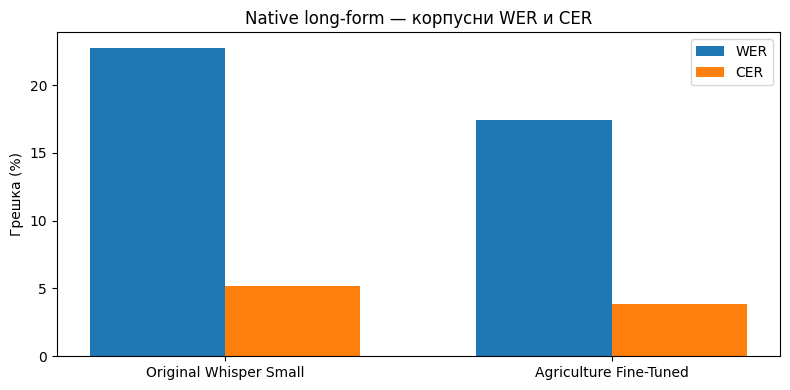

САЧУВАНИ ФАЈЛОВИ:
- all_recording_results.csv
- base_predictions.csv
- by_duration.csv
- by_speaker.csv
- critical_recordings_26_31_37_38.txt
- experiment_protocol.json
- finetuned_predictions.csv
- model_summary.csv
- top5_improvements.csv
- top5_regressions.csv
- transcription_comparison.csv
- wer_cer_comparison.png

Директоријум: /kaggle/working/native_longform_results


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(summary))
w = 0.35
ax.bar(x-w/2, summary.corpus_wer_pct, w, label="WER")
ax.bar(x+w/2, summary.corpus_cer_pct, w, label="CER")
ax.set_xticks(x, ["Original Whisper Small", "Agriculture Fine-Tuned"])
ax.set_ylabel("Грешка (%)")
ax.set_title("Native long-form — корпусни WER и CER")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "wer_cer_comparison.png", dpi=180)
plt.show()

protocol = {
    "benchmark": "Serbian General Speech ASR Benchmark — 40 recordings",
    "reference_path": str(REFERENCE_PATH), "audio_dir": str(AUDIO_DIR),
    "base_model": BASE_MODEL_PATH, "finetuned_model": str(FINETUNED_MODEL_PATH),
    "method": "WhisperForConditionalGeneration.generate native long-form, no pipeline/manual chunking",
    "feature_extraction": {"sample_rate": SAMPLE_RATE, "mono": True, "truncation": False,
                           "padding": "longest", "return_attention_mask": True},
    "decoding": DECODE,
    "precision": str(DTYPE), "device": DEVICE,
    "normalization": "NFKC, lowercase, Serbian Cyrillic-to-Latin, remove punctuation, normalize whitespace; digits not expanded",
    "timing": "Only model.generate, excludes audio loading, feature extraction and model loading; GPU synchronized",
    "speaker_overlap": "G1-G3 participated in agricultural training with other sentences; no unseen-speaker claim",
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "jiwer": version("jiwer"),
                 "librosa": librosa.__version__}
}
(OUTPUT_DIR / "experiment_protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
print("САЧУВАНИ ФАЈЛОВИ:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)
print("\nДиректоријум:", OUTPUT_DIR)

In [11]:
%pip -q install "datasets>=3,<5" "huggingface_hub>=0.30,<2"

Note: you may need to restart the kernel to use updated packages.


In [12]:
from datasets import load_dataset, Audio
from io import BytesIO
import soundfile as sf
import librosa
import numpy as np
import pandas as pd
from pathlib import Path

FLEURS_DIR = OUTPUT_DIR / "fleurs_sr_test"
FLEURS_DIR.mkdir(parents=True, exist_ok=True)

# Користимо искључиво тестни део српског FLEURS скупа.
# Streaming избегава преузимање свих језика и целог скупа.
fleurs_stream = load_dataset(
    "google/fleurs",
    "sr_rs",
    split="test",
    streaming=True
)

# Задржавамо оригиналне аудио-бајтове.
fleurs_stream = fleurs_stream.cast_column(
    "audio", Audio(decode=False)
)

fleurs_rows = []

for sample in fleurs_stream:
    if len(fleurs_rows) >= 100:
        break

    audio_info = sample["audio"]

    # Декодирање из оригиналних аудио-бајтова.
    if audio_info.get("bytes") is not None:
        audio, sr = sf.read(
            BytesIO(audio_info["bytes"]),
            dtype="float32"
        )
    else:
        audio, sr = sf.read(
            audio_info["path"],
            dtype="float32"
        )

    # Претварање у моно сигнал.
    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    # Whisper користи 16 kHz.
    if sr != 16000:
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=16000
        )
        sr = 16000

    audio = np.asarray(audio, dtype=np.float32)

    reference = str(sample["transcription"]).strip()
    assert len(audio) > 0 and reference

    # Чувамо локалну WAV копију ради поновљивости.
    idx = len(fleurs_rows) + 1
    wav_path = FLEURS_DIR / f"fleurs_{idx:02d}.wav"
    sf.write(wav_path, audio, sr)

    fleurs_rows.append({
        "id": idx,
        "fleurs_id": int(sample["id"]),
        "audio_path": str(wav_path),
        "reference": reference,
        "reference_normalized": normalize_sr(reference),
        "duration_s": len(audio) / sr
    })

fleurs_df = pd.DataFrame(fleurs_rows)

assert len(fleurs_df) == 100, "Није учитано свих 100 снимака."
# Провера да ли сваки снимак има јединствени редни број.
assert fleurs_df.id.is_unique, "Постоје дуплирани редни бројеви."

# Информација о поновљеним изворним FLEURS ID вредностима.
print("Број поновљених FLEURS ID вредности:",
      fleurs_df.fleurs_id.duplicated().sum())

fleurs_df.to_csv(
    FLEURS_DIR / "references.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Успешно учитано:", len(fleurs_df), "снимака")
print("Укупно трајање:", round(fleurs_df.duration_s.sum(), 2), "s")
display(fleurs_df[["id", "fleurs_id", "duration_s", "reference"]])

README.md: 0.00B [00:00, ?B/s]

Број поновљених FLEURS ID вредности: 7
Успешно учитано: 100 снимака
Укупно трајање: 1097.32 s


,id,fleurs_id,duration_s,reference
0,1,1969,12.30,у њему се наводи да је најупечатљивије место з...
1,2,1858,12.40,daniel lantanj ekspert un za bolesti izjavila ...
2,3,1871,5.28,u toploj klimi bliskog istoka kuća nije bila t...
3,4,1691,8.64,na nekim rutama veće kompanije imaju svoje sop...
4,5,1863,17.06,središte tibetanske meditacije je božanstvo jo...
...,...,...,...,...
95,96,1698,9.84,sve u svemiru je sačinjeno od materije celokup...
96,97,1991,8.10,tokom ovog perioda evropske istorije nad katol...
97,98,1960,14.70,navodno je bio u dvadesetim u izjavi biber je ...
98,99,1717,11.16,zbog podvodne topologije povratni tok je konce...


In [13]:
import torch
import time
import gc
import json

def test_fleurs_model(model_path, label):

    print("\nУчитавам:", label, flush=True)

    model, processor = load_model(model_path)
    records = []

    for i, row in fleurs_df.iterrows():

        audio, sr = librosa.load(
            row.audio_path,
            sr=SAMPLE_RATE,
            mono=True
        )

        # Цео снимак се прослеђује Whisper моделу.
        # Нема ручног сечења ни pipeline сегментације.
        features = processor.feature_extractor(
            audio,
            sampling_rate=SAMPLE_RATE,
            return_tensors="pt",
            truncation=False,
            padding="longest",
            return_attention_mask=True
        )

        input_features = features.input_features.to(
            device=DEVICE,
            dtype=DTYPE
        )
        attention_mask = features.attention_mask.to(DEVICE)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.inference_mode():
            generated = model.generate(
                input_features=input_features,
                attention_mask=attention_mask,
                **DECODE
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        hypothesis = processor.batch_decode(
            generated,
            skip_special_tokens=True
        )[0].strip()

        reference_norm = normalize_sr(row.reference)
        hypothesis_norm = normalize_sr(hypothesis)

        wer = jiwer.wer(reference_norm, hypothesis_norm) * 100
        cer = jiwer.cer(reference_norm, hypothesis_norm) * 100

        records.append({
            "id": int(row.id),
            "fleurs_id": int(row.fleurs_id),
            "model": label,
            "reference": row.reference,
            "hypothesis": hypothesis,
            "reference_normalized": reference_norm,
            "hypothesis_normalized": hypothesis_norm,
            "duration_s": float(row.duration_s),
            "inference_s": elapsed,
            "rtf": elapsed / float(row.duration_s),
            "wer_pct": wer,
            "cer_pct": cer
        })

        # Чување после сваког снимка.
        pd.DataFrame(records).to_csv(
            FLEURS_DIR / (
                "original_results.csv"
                if label == "Original Whisper Small"
                else "finetuned_results.csv"
            ),
            index=False,
            encoding="utf-8-sig"
        )

        print(
            f"[{label}] {i+1:02d}/100 | "
            f"WER={wer:.2f}% | CER={cer:.2f}%",
            flush=True
        )

        del features, input_features, attention_mask, generated

    del model, processor
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pd.DataFrame(records)


# Оригинални модел
fleurs_original = test_fleurs_model(
    BASE_MODEL_PATH,
    "Original Whisper Small"
)

# Адаптирани модел
fleurs_finetuned = test_fleurs_model(
    FINETUNED_MODEL_PATH,
    "Agriculture Fine-Tuned Whisper Small"
)

print("\nОба модела су завршила FLEURS тест.")


Учитавам: Original Whisper Small
[Original Whisper Small] 01/100 | WER=45.83% | CER=17.69%
[Original Whisper Small] 02/100 | WER=26.67% | CER=4.90%
[Original Whisper Small] 03/100 | WER=50.00% | CER=19.30%
[Original Whisper Small] 04/100 | WER=14.29% | CER=6.03%
[Original Whisper Small] 05/100 | WER=23.81% | CER=5.59%
[Original Whisper Small] 06/100 | WER=44.00% | CER=11.88%
[Original Whisper Small] 07/100 | WER=58.33% | CER=25.35%
[Original Whisper Small] 08/100 | WER=46.43% | CER=14.72%
[Original Whisper Small] 09/100 | WER=20.00% | CER=4.12%
[Original Whisper Small] 10/100 | WER=23.08% | CER=10.98%
[Original Whisper Small] 11/100 | WER=85.71% | CER=22.88%
[Original Whisper Small] 12/100 | WER=35.29% | CER=6.73%
[Original Whisper Small] 13/100 | WER=44.12% | CER=25.00%
[Original Whisper Small] 14/100 | WER=33.33% | CER=7.84%
[Original Whisper Small] 15/100 | WER=23.81% | CER=4.41%
[Original Whisper Small] 16/100 | WER=17.65% | CER=7.14%
[Original Whisper Small] 17/100 | WER=28.57% |

In [14]:
# Израчунавање корпусних метрика.
def fleurs_metrics(frame):

    references = frame["reference_normalized"].tolist()
    hypotheses = frame["hypothesis_normalized"].tolist()

    return {
        "corpus_wer_pct": jiwer.wer(references, hypotheses) * 100,
        "corpus_cer_pct": jiwer.cer(references, hypotheses) * 100,
        "mean_recording_wer_pct": frame.wer_pct.mean(),
        "total_audio_s": frame.duration_s.sum(),
        "total_inference_s": frame.inference_s.sum(),
        "aggregate_rtf": (
            frame.inference_s.sum() / frame.duration_s.sum()
        )
    }


original_metrics = fleurs_metrics(fleurs_original)
finetuned_metrics = fleurs_metrics(fleurs_finetuned)

summary_fleurs = pd.DataFrame([
    {"model": "Original Whisper Small", **original_metrics},
    {"model": "Agriculture Fine-Tuned Whisper Small", **finetuned_metrics}
])

print("=== FLEURS SRPSKI — 100 TEST SNIMAKA ===")
display(summary_fleurs.round(3))

wer_original = original_metrics["corpus_wer_pct"]
wer_finetuned = finetuned_metrics["corpus_wer_pct"]

print(f"\nOriginal WER: {wer_original:.2f}%")
print(f"Fine-tuned WER: {wer_finetuned:.2f}%")
print(f"Промена WER: {wer_finetuned - wer_original:+.2f} pp")

if wer_original > 0:
    relative_change = (
        (wer_finetuned - wer_original) / wer_original * 100
    )
    print(f"Релативна промена WER: {relative_change:+.2f}%")

# Поређење сваког појединачног снимка.
comparison_fleurs = fleurs_original[
    ["id", "fleurs_id", "reference", "hypothesis", "wer_pct", "cer_pct"]
].rename(columns={
    "hypothesis": "original_transcription",
    "wer_pct": "original_wer_pct",
    "cer_pct": "original_cer_pct"
}).merge(
    fleurs_finetuned[
        ["id", "hypothesis", "wer_pct", "cer_pct"]
    ].rename(columns={
        "hypothesis": "finetuned_transcription",
        "wer_pct": "finetuned_wer_pct",
        "cer_pct": "finetuned_cer_pct"
    }),
    on="id",
    validate="one_to_one"
)

comparison_fleurs["wer_delta_pp"] = (
    comparison_fleurs.finetuned_wer_pct
    - comparison_fleurs.original_wer_pct
)

print("\n=== РЕЗУЛТАТИ ПО СНИМКУ ===")
display(comparison_fleurs.round(2))

print("\n=== НАЈВЕЋА ПОБОЉШАЊА ===")
display(
    comparison_fleurs.nsmallest(5, "wer_delta_pp").round(2)
)

print("\n=== НАЈВЕЋА ПОГОРШАЊА ===")
display(
    comparison_fleurs.nlargest(5, "wer_delta_pp").round(2)
)

# Чување свих резултата и параметара.
summary_fleurs.to_csv(
    FLEURS_DIR / "summary.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison_fleurs.to_csv(
    FLEURS_DIR / "comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

fleurs_protocol = {
    "dataset": "google/fleurs",
    "language_config": "sr_rs",
    "split": "test",
    "selection": "first 100 unique recordings in dataset order",
    "number_of_recordings": len(fleurs_df),
    "base_model": str(BASE_MODEL_PATH),
    "finetuned_model": str(FINETUNED_MODEL_PATH),
    "decoding": DECODE,
    "dtype": str(DTYPE),
    "device": str(DEVICE),
    "speaker_independence": (
        "External dataset; speaker identities not independently verified"
    )
}

(FLEURS_DIR / "protocol.json").write_text(
    json.dumps(fleurs_protocol, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nСви резултати сачувани у:", FLEURS_DIR)

=== FLEURS SRPSKI — 100 TEST SNIMAKA ===


,model,corpus_wer_pct,corpus_cer_pct,mean_recording_wer_pct,total_audio_s,total_inference_s,aggregate_rtf
0,Original Whisper Small,37.984,10.568,38.856,1097.32,93.354,0.085
1,Agriculture Fine-Tuned Whisper Small,40.428,12.294,41.311,1097.32,96.094,0.088



Original WER: 37.98%
Fine-tuned WER: 40.43%
Промена WER: +2.44 pp
Релативна промена WER: +6.43%

=== РЕЗУЛТАТИ ПО СНИМКУ ===


,id,fleurs_id,reference,original_transcription,original_wer_pct,original_cer_pct,finetuned_transcription,finetuned_wer_pct,finetuned_cer_pct,wer_delta_pp
0,1,1969,у њему се наводи да је најупечатљивије место з...,U njemu se navodite da je najupe čatljivije me...,45.83,17.69,U njemu se navodi da je najupečatljilije mesto...,50.00,17.69,4.17
1,2,1858,daniel lantanj ekspert un za bolesti izjavila ...,"Daniel Lantanj, expert UM za bolesti izjavila ...",26.67,4.90,"Danjel Lantać, ekspert uM za bolesti izjavljil...",46.67,9.80,20.00
2,3,1871,u toploj klimi bliskog istoka kuća nije bila t...,U tople klimi bliskog istuka kuća nije to riko...,50.00,19.30,U topleg klimi blijskog istuka kuća nije tolji...,60.00,19.30,10.00
3,4,1691,na nekim rutama veće kompanije imaju svoje sop...,Na nekim rutama veće kompanije imaju svoje sob...,14.29,6.03,Na nekim rutama veće kompani imaju svoje sopst...,33.33,9.48,19.05
4,5,1863,središte tibetanske meditacije je božanstvo jo...,Središte tibetanske meditaće je božanstvo yoga...,23.81,5.59,Sredljište tibetanske meditacije je božanstvo ...,28.57,6.83,4.76
...,...,...,...,...,...,...,...,...,...,...
95,96,1698,sve u svemiru je sačinjeno od materije celokup...,Sve u sve miro je sačinio od materije. Celog k...,38.89,7.96,Sve u sve miro je sačenje od materije. Celog k...,55.56,14.16,16.67
96,97,1991,tokom ovog perioda evropske istorije nad katol...,"Tokom ovog perioda evropskih istorije, nad kat...",25.00,9.48,Tokom ovog perioda evropskih istorije nad kata...,35.00,12.93,10.00
97,98,1960,navodno je bio u dvadesetim u izjavi biber je ...,"Navodno je bio u 20. U izjavi Biberija rekao, ...",41.38,14.02,Navodno je bio u dvadesetim u izjavlji biberij...,48.28,9.15,6.90
98,99,1717,zbog podvodne topologije povratni tok je konce...,Zbog podvodne topologije povratni toke koncent...,23.81,5.34,Zbog poodvodne topologije povratni tok je konc...,14.29,2.29,-9.52



=== НАЈВЕЋА ПОБОЉШАЊА ===


,id,fleurs_id,reference,original_transcription,original_wer_pct,original_cer_pct,finetuned_transcription,finetuned_wer_pct,finetuned_cer_pct,wer_delta_pp
36,37,1975,vatikan ima oko 800 stanovnika to je najmanja ...,Vatika nimo okosnostu stonovnika. To je najman...,61.11,13.51,"Vatika nimo okosnostu stanovnika, to je najman...",33.33,11.71,-27.78
10,11,1872,tokom borbe za nezavisnost u organizaciji pokr...,Tokom bordved za nezavisnost organizaciji pokr...,85.71,22.88,Tokom borbeća nezavisnost u organizaciji pokre...,61.90,15.69,-23.81
48,49,1862,nextgen je sistem za koji faa tvrdi da će omog...,"Next genius system, za koji FAA tvrdi da će om...",63.33,15.52,Nekst genje sistem za koji FAA tvrdi da će omo...,40.00,12.07,-23.33
75,76,1921,s druge strane snežni i ledeni uslovi su norma...,"Z druge strane, snežnje ledeni uslovi su norma...",68.18,26.56,Z druge strane snježnje ledani uslovi su norma...,45.45,13.28,-22.73
58,59,1700,tanji je pod lunarnim morem a deblji pod brdima,"Tanje pod lunarnim overem, a debil pod Brdima.",44.44,19.15,"Tanje je pod lunarnim morrem, a deblji pod brd...",22.22,4.26,-22.22



=== НАЈВЕЋА ПОГОРШАЊА ===


,id,fleurs_id,reference,original_transcription,original_wer_pct,original_cer_pct,finetuned_transcription,finetuned_wer_pct,finetuned_cer_pct,wer_delta_pp
30,31,1826,nakon nesreće gibson je prevezen u bolnicu ali...,"Nakon neseće, Gibson je prevezan u boljicu ali...",45.45,10.94,"Nako ne seće, gipsan je prevjezanu boljicu, al...",81.82,18.75,36.36
8,9,1721,po izgradnji brane 1963. godine zaustavljene s...,Po izgranji brane 1963 godine zaustavljene su ...,20.00,4.12,Poizgradnje brane hiljdevst štedeće godine zau...,53.33,24.74,33.33
82,83,1827,kora je debela otprilike 70 km na bližoj stran...,Koraja debila ok preljike 70 km na bližu istra...,53.33,17.81,Korea debe lok prilike sedamdeset kilometrana ...,80.00,63.01,26.67
54,55,1920,obično imaju posebnu ponudu hrane pića i zabav...,"Ovečno imaju posebno ponadu hrane, picje i zab...",23.81,7.83,"Ovečno imaju posebno polandu hrane, pića i zab...",47.62,18.26,23.81
1,2,1858,daniel lantanj ekspert un za bolesti izjavila ...,"Daniel Lantanj, expert UM za bolesti izjavila ...",26.67,4.90,"Danjel Lantać, ekspert uM za bolesti izjavljil...",46.67,9.80,20.00



Сви резултати сачувани у: /kaggle/working/native_longform_results/fleurs_sr_test


### Rezultati na FLEURS skupu

Na 100 FLEURS snimaka korpusni WER povećan je sa 37,98% na 40,43%, odnosno za 2,44 procentna poena. Za razliku od glavnog skupa, domenska adaptacija ovde nije donela poboljšanje, što ukazuje na ograničenja generalizacije.

In [15]:
import hashlib
import pandas as pd
from pathlib import Path

# 1. Израчунавање SHA-256 хеша сваког WAV снимка.
# Идентичан хеш означава идентичан садржај WAV датотеке.

def audio_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

fleurs_df["audio_hash"] = fleurs_df["audio_path"].apply(audio_hash)

# 2. Провера дупликата
duplicate_audio = fleurs_df.duplicated(
    subset=["audio_hash"], keep=False
)

duplicate_text = fleurs_df.duplicated(
    subset=["reference_normalized"], keep=False
)

duplicate_ids = fleurs_df.duplicated(
    subset=["fleurs_id"], keep=False
)

print("=" * 60)
print("ПРОВЕРА ДУПЛИКАТА — FLEURS 100")
print("=" * 60)

print("Укупно снимака:", len(fleurs_df))

print(
    "Број сувишних идентичних WAV снимака:",
    fleurs_df["audio_hash"].duplicated().sum()
)

print(
    "Број сувишних идентичних транскрипција:",
    fleurs_df["reference_normalized"].duplicated().sum()
)

print(
    "Број поновљених FLEURS ID вредности:",
    fleurs_df["fleurs_id"].duplicated().sum()
)

# 3. Приказ свих дупликата

if duplicate_audio.any():
    print("\nИДЕНТИЧНИ WAV СНИМЦИ:")
    display(
        fleurs_df.loc[
            duplicate_audio,
            ["id", "fleurs_id", "duration_s", "reference"]
        ].sort_values("fleurs_id")
    )
else:
    print("\nНема идентичних WAV снимака.")

if duplicate_text.any():
    print("\nПОНОВЉЕНЕ РЕФЕРЕНТНЕ РЕЧЕНИЦЕ:")
    display(
        fleurs_df.loc[
            duplicate_text,
            ["id", "fleurs_id", "reference"]
        ].sort_values("reference")
    )
else:
    print("\nНема идентичних референтних реченица.")

if duplicate_ids.any():
    print("\nПОНОВЉЕНИ FLEURS ID-ЈЕВИ:")
    display(
        fleurs_df.loc[
            duplicate_ids,
            ["id", "fleurs_id", "duration_s", "reference"]
        ].sort_values("fleurs_id")
    )

# 4. Коначан закључак

print("\n" + "=" * 60)

if not duplicate_audio.any() and not duplicate_text.any():
    print("ЗАКЉУЧАК: Нема идентичних WAV датотека")
    print("нити идентичних нормализованих транскрипција.")
    print("Свих 100 записа могу остати у тесту.")
else:
    print("ЗАКЉУЧАК: Пронађени су потенцијални дупликати.")
    print("Потребно је прегледати приказане снимке.")

print("=" * 60)

ПРОВЕРА ДУПЛИКАТА — FLEURS 100
Укупно снимака: 100
Број сувишних идентичних WAV снимака: 0
Број сувишних идентичних транскрипција: 7
Број поновљених FLEURS ID вредности: 7

Нема идентичних WAV снимака.

ПОНОВЉЕНЕ РЕФЕРЕНТНЕ РЕЧЕНИЦЕ:


,id,fleurs_id,reference
26,27,1787,blogovanje je alat koji nadahnjuje saradnju i ...
90,91,1787,blogovanje je alat koji nadahnjuje saradnju i ...
74,75,1756,kasno u nedelju predsednik sjedinjenih američk...
84,85,1756,kasno u nedelju predsednik sjedinjenih američk...
25,26,1827,kora je debela otprilike 70 km na bližoj stran...
82,83,1827,kora je debela otprilike 70 km na bližoj stran...
22,23,1920,obično imaju posebnu ponudu hrane pića i zabav...
54,55,1920,obično imaju posebnu ponudu hrane pića i zabav...
58,59,1700,tanji je pod lunarnim morem a deblji pod brdima
83,84,1700,tanji je pod lunarnim morem a deblji pod brdima



ПОНОВЉЕНИ FLEURS ID-ЈЕВИ:


,id,fleurs_id,duration_s,reference
58,59,1700,6.12,tanji je pod lunarnim morem a deblji pod brdima
83,84,1700,6.44,tanji je pod lunarnim morem a deblji pod brdima
98,99,1717,11.16,zbog podvodne topologije povratni tok je konce...
21,22,1717,10.08,zbog podvodne topologije povratni tok je konce...
74,75,1756,13.10,kasno u nedelju predsednik sjedinjenih američk...
84,85,1756,10.44,kasno u nedelju predsednik sjedinjenih američk...
26,27,1787,9.42,blogovanje je alat koji nadahnjuje saradnju i ...
90,91,1787,8.40,blogovanje je alat koji nadahnjuje saradnju i ...
25,26,1827,7.38,kora je debela otprilike 70 km na bližoj stran...
82,83,1827,7.50,kora je debela otprilike 70 km na bližoj stran...



ЗАКЉУЧАК: Пронађени су потенцијални дупликати.
Потребно је прегледати приказане снимке.


### Zaključak

Domenska adaptacija poboljšala je tačnost na poljoprivrednom i glavnom skupu srpskog govora, dok je na FLEURS skupu zabeleženo pogoršanje. Rezultati pokazuju da uspešnost adaptacije zavisi od karakteristika test podataka i da poboljšanje u jednom domenu ne garantuje bolje rezultate na drugim skupovima.